## Importation des bibliothèques

In [1]:
# Classification des images par ambiance
import os
from PIL import Image
from sklearn.cluster import KMeans
import numpy as np
import shutil
import random
import colorsys
import matplotlib.pyplot as plt
from tqdm import tqdm

In [2]:
from google.colab import drive
drive.mount('/content/drive')

folder = "/content/drive/MyDrive/projet IA generative/dataset/data"
dataset_path = "/content/drive/MyDrive/projet IA generative/dataset/data_final"
os.makedirs(dataset_path, exist_ok=True)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


# **1. Importation, netoyage et classement du dataset**

## Suppression des images erronées

In [ ]:
for img_name in os.listdir(folder):
    path = os.path.join(folder, img_name)
    if os.path.isfile(path):  # Vérifie si le dossier du dataset existe
        try:
            Image.open(path).verify()
        except:
            print("Une image erronée a été détectée, elle sera supprimée")
            os.remove(path)
    else:
        print(f"Erreur lors de l'ouverture du dossier")

In [ ]:
nb_files = len([
    f for f in os.listdir(folder)
    if os.path.isfile(os.path.join(folder, f))
])

print(f"Nombre total d'images : {nb_files}")

Nombre total d'images : 4317


## Organiser les images par ambiance chromatique

### Extraction des couleurs dominantes de chaque image

In [3]:
ambiances = ["chaud", "froid", "sombre", "doux", "naturel", "neutre"]

In [ ]:
for ambiance in ambiances:
    os.makedirs(os.path.join(dataset_path, ambiance), exist_ok=True)

# Extraction des couleurs dominantes
def dominant_colors(path, k=5):
    img = Image.open(path).convert("RGB").resize((64, 64))
    arr = np.array(img).reshape(-1, 3)

    kmeans = KMeans(n_clusters=k, random_state=0).fit(arr)
    return kmeans.cluster_centers_

# Conversion RGB-HSV
def rgb_to_hsv(color):
    r, g, b = color / 255.0
    return colorsys.rgb_to_hsv(r, g, b)

###classification des images par ambiance

In [ ]:
# Score perceptuel par ambiance
def score_ambiance(colors, min_score=4):
    scores = {
        "chaud": 0,
        "froid": 0,
        "sombre": 0,
        "doux": 0,
        "naturel": 0
    }

    for color in colors:
        h, s, v = rgb_to_hsv(color)
        if h < 0.15 or h > 0.9:
            scores["chaud"] += 2
        if 0.5 < h < 0.75:
            scores["froid"] += 2
        if v < 0.35:
            scores["sombre"] += 2
        if s < 0.35 and v > 0.65:
            scores["doux"] += 2
        if 0.2 < h < 0.45:
            scores["naturel"] += 1.5

    best = max(scores, key=scores.get)
    if scores[best] < min_score:
        return "neutre"

    return best

In [ ]:
# Classification finale
for file in tqdm(os.listdir(folder)):
    path = os.path.join(folder, file)

    try:
        colors = dominant_colors(path)
        ambiance = score_ambiance(colors)
        shutil.copy(path, os.path.join(dataset_path, ambiance, file))

    except Exception as e:
        print(f"{e}")

 61%|██████    | 2612/4317 [21:53<12:58,  2.19it/s]

In [ ]:
# Compter le nombre total d'images pour chaque ambiance
for ambiance in ambiances :
    ambiance_path = os.path.join(dataset_path, ambiance)
    count = len([
        f for f in os.listdir(ambiance_path)
        if os.path.isfile(os.path.join(ambiance_path, f))
    ])
    print(f"Nombre d'images dans l'ambiance '{ambiance}' : {count}")

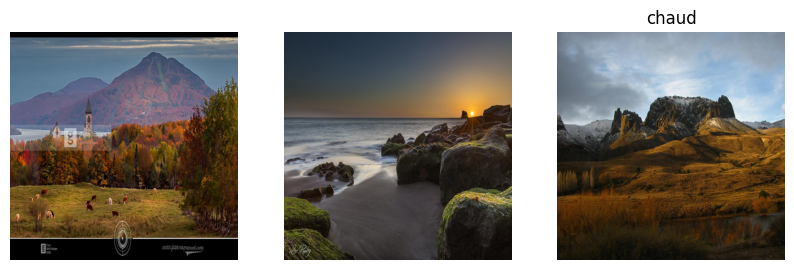

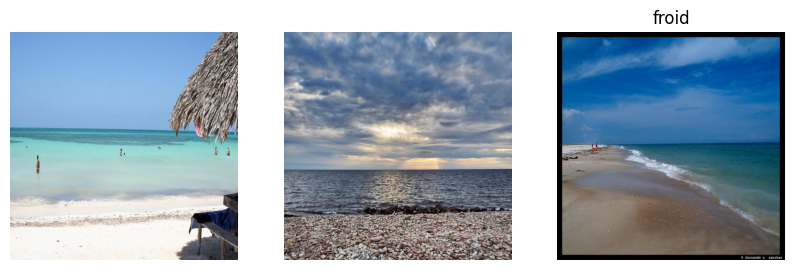

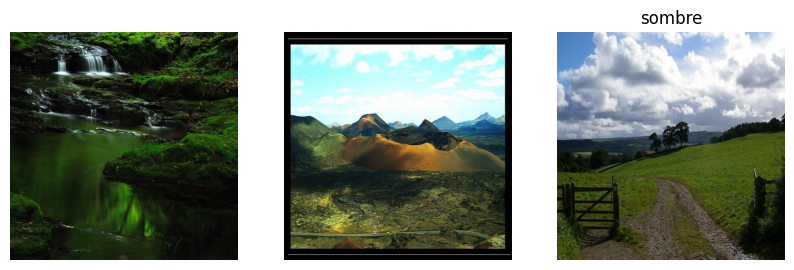

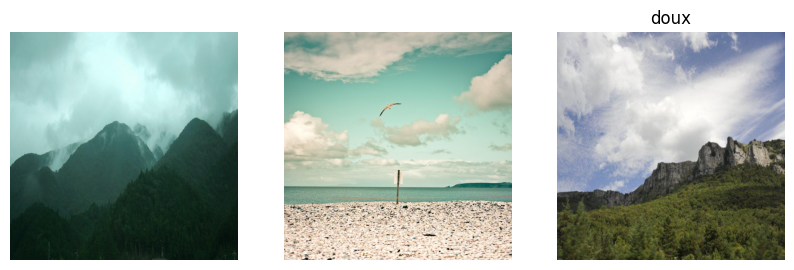

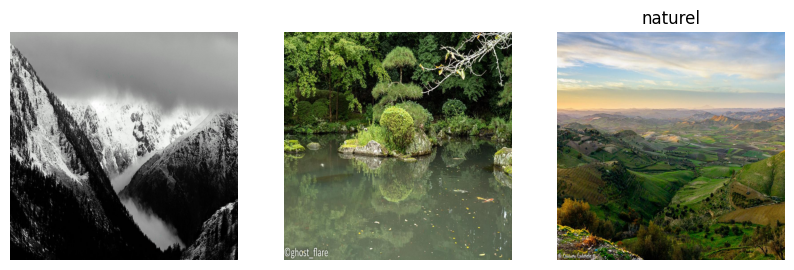

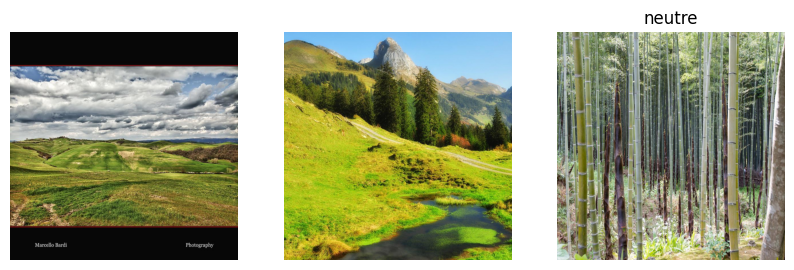

In [4]:
# Afficher quelques images par ambiance
for ambiance in ambiances :
    ambiance_path = os.path.join(dataset_path, ambiance)
    images = [
        f for f in os.listdir(ambiance_path)
        if os.path.isfile(os.path.join(ambiance_path, f))
    ]
    sample_images = random.sample(images, min(3, len(images)))

    plt.figure(figsize=(10, 4))
    for i, img_name in enumerate(sample_images):
        img_path = os.path.join(ambiance_path, img_name)
        img = Image.open(img_path).resize((512, 512))

        plt.subplot(1, 3, i + 1)
        plt.imshow(img)
        plt.axis('off')

    plt.title(f"{ambiance}")
    plt.show()

# **2. Création du trainset et préparation pour le modèle**

In [5]:
import tensorflow as tf

In [6]:
IMG_SIZE = (256, 256)
IMG_CHANNELS = 3
BATCH_SIZE = 32
SEED = 42
LATENT_DIM = 128
AUTOTUNE = tf.data.AUTOTUNE

In [7]:
dataset = tf.keras.preprocessing.image_dataset_from_directory(
    dataset_path,
    labels="inferred",
    label_mode="int",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=True
)

Found 4380 files belonging to 6 classes.


In [8]:
class_names = dataset.class_names
NUM_CLASSES = len(class_names)
print(class_names)

['chaud', 'doux', 'froid', 'naturel', 'neutre', 'sombre']


## Encodage des labels et normalisation

In [9]:
def normalize(images, labels):
    images = tf.cast(images, tf.float32) / 255.0
    labels = tf.one_hot(tf.cast(labels, tf.int32), NUM_CLASSES)
    labels = tf.cast(labels, tf.float32)
    print(labels)
    return images, labels

dataset = dataset.map(normalize, num_parallel_calls=tf.data.AUTOTUNE)
dataset = dataset.prefetch(tf.data.AUTOTUNE)

Tensor("one_hot:0", shape=(None, 6), dtype=float32)


In [10]:
images, labels = next(iter(dataset))

print("Images:", images.dtype, tf.reduce_min(images), tf.reduce_max(images))
print("Labels:", labels.shape, labels[0])

Images: <dtype: 'float32'> tf.Tensor(0.0, shape=(), dtype=float32) tf.Tensor(1.0, shape=(), dtype=float32)
Labels: (32, 6) tf.Tensor([0. 0. 1. 0. 0. 0.], shape=(6,), dtype=float32)


# **3. Construction de l'encodeur, reparamétrisation et décodeur**

In [11]:
from tensorflow.keras import layers, Model

## Encodeur

In [12]:
def encoder() :
    IMG_WIDTH, IMG_HEIGHT = IMG_SIZE[0], IMG_SIZE[1]
    img_input = layers.Input(
        shape=(IMG_HEIGHT, IMG_WIDTH, IMG_CHANNELS),
        name="image_input"
    )

    label_input = layers.Input(
        shape=(NUM_CLASSES,),
        name="label_input"
    )

    # Embedding du label (conditionnement spatial)
    label_embedding = layers.Dense(
        IMG_HEIGHT * IMG_WIDTH,
        activation="relu"
    )(label_input)

    label_embedding = layers.Reshape(
        (IMG_HEIGHT, IMG_WIDTH, 1)
    )(label_embedding)

    # Concat image + label
    x = layers.Concatenate()([img_input, label_embedding])

    # Downsampling
    x = layers.Conv2D(32, 4, strides=2, padding="same", activation="relu")(x)
    x = layers.Conv2D(64, 4, strides=2, padding="same", activation="relu")(x)
    x = layers.Conv2D(128, 4, strides=2, padding="same", activation="relu")(x)
    x = layers.Conv2D(256, 4, strides=2, padding="same", activation="relu")(x)

    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(256, activation="relu")(x)

    z_mean = layers.Dense(LATENT_DIM, name="z_mean")(x)
    z_log_var = layers.Dense(LATENT_DIM, name="z_log_var")(x)

    return Model(
        [img_input, label_input],
        [z_mean, z_log_var],
        name="encoder"
    )

## Décodeur

In [13]:
def decoder():
    z_input = layers.Input(shape=(LATENT_DIM,), name="z_input")
    label_input = layers.Input(shape=(NUM_CLASSES,), name="label_input")

    x = layers.Concatenate()([z_input, label_input])

    x = layers.Dense(8 * 8 * 256, activation="relu")(x)
    x = layers.Reshape((8, 8, 256))(x)

    # Upsampling
    x = layers.Conv2DTranspose(256, 4, strides=2, padding="same", activation="relu")(x)
    x = layers.Conv2DTranspose(128, 4, strides=2, padding="same", activation="relu")(x)
    x = layers.Conv2DTranspose(64, 4, strides=2, padding="same", activation="relu")(x)
    x = layers.Conv2DTranspose(32, 4, strides=2, padding="same", activation="relu")(x)
    x = layers.Conv2DTranspose(16, 4, strides=2, padding="same", activation="relu")(x)

    output = layers.Conv2D(
        IMG_CHANNELS,
        kernel_size=3,
        padding="same",
        activation="sigmoid"
    )(x)

    return Model(
        [z_input, label_input],
        output,
        name="decoder"
    )

# **4. Construction du modèle de VAE complet**

In [14]:
class CVAE(tf.keras.Model):
    def __init__(self):
        super(CVAE, self).__init__()

        self.encoder = encoder()
        self.decoder = decoder()

    def encode(self, images, labels):
        z_mean, z_log_var = self.encoder([images, labels])
        return z_mean, z_log_var

    def reparameterize(self, mean, log_var):
        eps = tf.random.normal(shape=tf.shape(mean))
        return mean + tf.exp(0.5 * log_var) * eps

    def decode(self, z, labels, apply_sigmoid=True):
        reconstruction = self.decoder([z, labels])
        if apply_sigmoid:
            return reconstruction
        return reconstruction

    def call(self, inputs):
        images, labels = inputs
        z_mean, z_log_var = self.encode(images, labels)
        z = self.reparameterize(z_mean, z_log_var)
        return self.decode(z, labels)

## Fonction de perte et optimiseur

In [15]:
optimizer = tf.keras.optimizers.Adam(1e-3)

# Fonction pour calculer la log-probabilité d'un échantillon selon une distribution normale
def log_normal_pdf(sample, mean, logvar, raxis=1):
    log2pi = tf.math.log(2. * np.pi)
    return tf.reduce_sum(
        -.5 * ((sample - mean) ** 2. * tf.exp(-logvar) + logvar + log2pi),
        axis=raxis)

# Fonction pour calculer la perte du modèle
def compute_loss(model, images, labels):
    z_mean, z_log_var = model.encoder([images, labels])
    z = model.reparameterize(z_mean, z_log_var)
    reconstruction = model.decoder([z, labels])

    # Reconstruction loss
    recon_loss = tf.reduce_sum(
        tf.keras.losses.binary_crossentropy(images, reconstruction),
        axis=[1, 2]
    )

    # KL divergence
    kl_loss = -0.5 * tf.reduce_sum(
        1 + z_log_var - tf.square(z_mean) - tf.exp(z_log_var),
        axis=1
    )

    return tf.reduce_mean(recon_loss + kl_loss)

# Définition d'une fonction pour exécuter une étape d'entraînement et retourner le loss
@tf.function
def train_step(model, images, labels, optimizer):
    with tf.GradientTape() as tape:
        loss = compute_loss(model, images, labels)

    gradients = tape.gradient(loss, model.trainable_variables)
    optimizer.apply_gradients(zip(gradients, model.trainable_variables))

    return loss

## Entrainement

In [16]:
epochs = 150
model = CVAE()

In [ ]:
for epoch in range(epochs):
    print(f"\nEpoch {epoch + 1}/{epochs}")
    epoch_loss = []

    for images, labels in tqdm(dataset):
        loss = train_step(model, images, labels, optimizer)
        epoch_loss.append(loss)

    print(f"Loss moyen : {tf.reduce_mean(epoch_loss):.4f}")

# **5. TeGénération des images**

In [20]:
def generate_images(ambiance, n, noise_scale=0.3):
    if ambiance not in ambiances:
        raise ValueError(
            f"L'ambiance '{ambiance}' est inconnue\n"
            f"Ambiances disponibles : {list(ambiances.keys())}"
        )

    target_label = class_names.index(ambiance)
    imgs = []

    for images, labels in dataset:
        labels_batch = tf.argmax(labels, axis=-1)
        mask = tf.where(labels_batch == target_label)

        if tf.shape(mask)[0] > 0:
            idx = mask[0][0]

            image = tf.expand_dims(images[idx], axis=0)
            label_for_model = tf.expand_dims(labels[idx], axis=0)

            z_mean, _ = model.encoder([image, label_for_model])
            z = z_mean + noise_scale * tf.random.normal(tf.shape(z_mean))
            generated = model.decoder([z, label_for_model])

            imgs.append(generated[0].numpy())

            if len(imgs) == n:
                break

    imgs = tf.clip_by_value(imgs, 0, 1)

    plt.figure(figsize=(15, 3))
    for i in range(len(imgs)):
        plt.subplot(1, n, i + 1)
        plt.imshow(imgs[i])
        plt.axis("off")

    plt.suptitle(f"Génération – ambiance '{ambiance}'")
    plt.show()

    return imgs

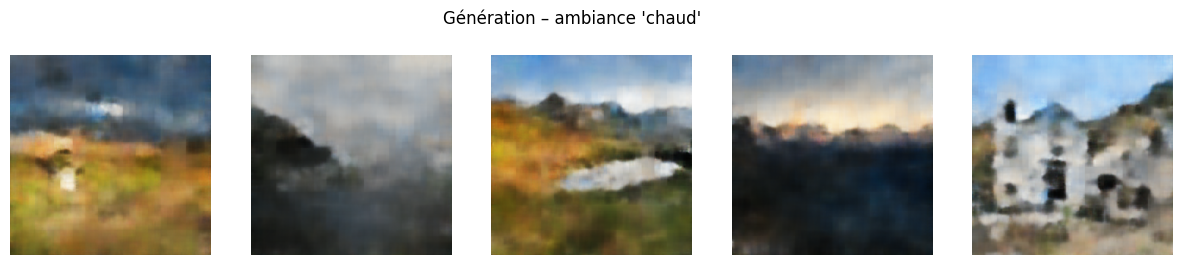

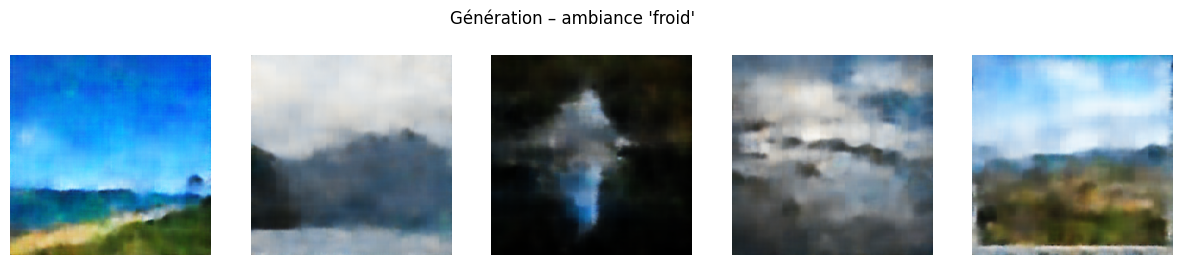

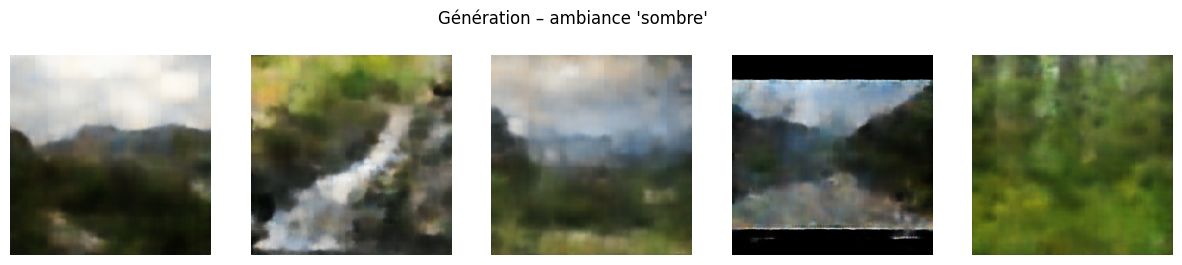

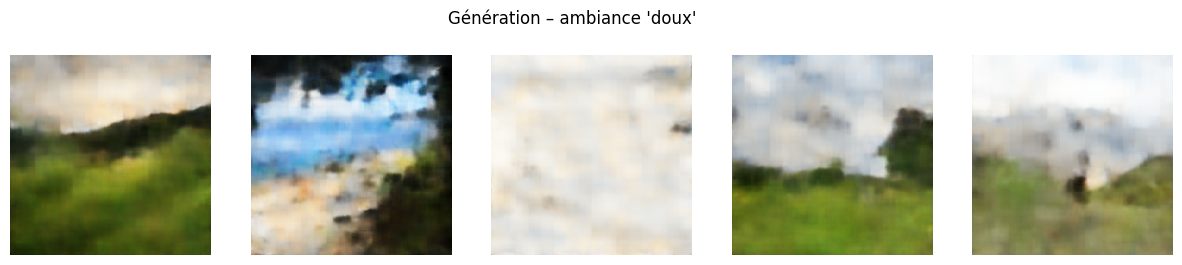

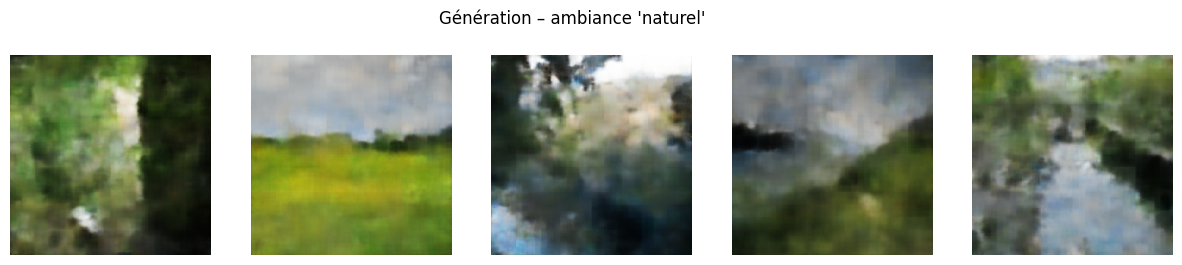

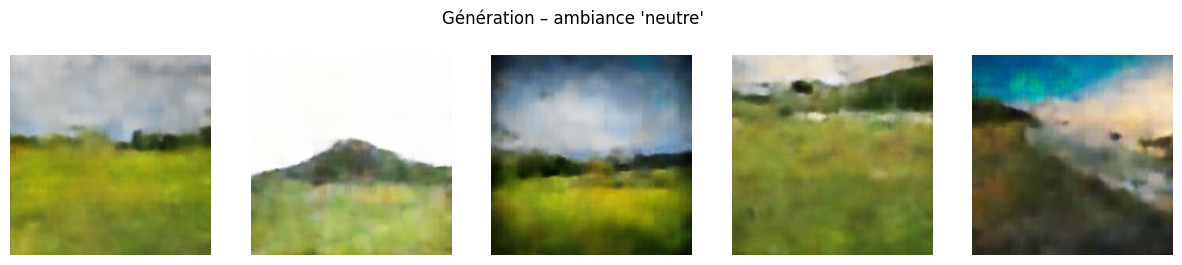

In [22]:
generated_images = {
    'chaud': generate_images("chaud", 5),
    'froid': generate_images("froid", 5),
    'sombre': generate_images("sombre", 5),
    'doux': generate_images("doux", 5),
    'naturel': generate_images("naturel", 5),
    'neutre': generate_images("neutre", 5)
}

## Sauvegarde des images générées

In [23]:
generated_path = "/content/drive/MyDrive/projet IA generative/generated"
os.makedirs(generated_path, exist_ok=True)

In [24]:
# Sauvegarde des images générées
for ambiance, imgs in generated_images.items():
    ambiance_path = os.path.join(generated_path, ambiance)
    os.makedirs(ambiance_path, exist_ok=True)

    for i, img in enumerate(imgs):
        img = np.clip(img, 0, 1)
        img = (img * 255).astype(np.uint8)

        img_pil = Image.fromarray(img)
        img_path = os.path.join(ambiance_path, f"{ambiance}_{i}.png")
        img_pil.save(img_path)

print("Les images ont été sauvegardées avec succès")

Les images ont été sauvegardées avec succès


# **6. Sauvegarde des poids du modèle**

In [ ]:
model_path = "/content/drive/MyDrive/projet IA generative/model"
os.makedirs(model_path, exist_ok=True)

In [ ]:
for images_sample, labels_sample in dataset.take(1):
    _ = model([images_sample, labels_sample])
    break

model.save_weights(os.path.join(model_path, "cvae_model.weights.h5"))
print("Poids du modèle sauvegardés avec succès")